# Pipeline demo: one run, step by step

This notebook follows **one dataset through one run** of the benchmarking workflow, from the source files
to the evaluated Leiden clusters. For every step it shows the **input**, runs the step with **the same functions
the pipeline's script calls**, and shows the **output**.

```
prepare ──► preprocess ──► benchmark ──► permutation_test ──► aggregate_runs
                      └──► embed (2D UMAP, for plots only)
```

**The run shown here**

| choice | value |
|---|---|
| dataset | `GSE118767_celseq2_3cl` (CellBench; Tian et al., 2019): 3 human lung adenocarcinoma cell lines (H1975, H2228, HCC827), CEL-seq2 |
| normalization | `log_cpm` |
| representation | `pca` |
| algorithm | `leiden`, with its default parameters |

The tuning steps (`tune`, `aggregate_tuning`) are left out: this is the `default` run.

In the pipeline, each step saves its output to a file that the next step reads; each step below names that file.

## Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

# Find the project root (the folder with the Snakefile), so the notebook runs from any folder
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Snakefile").exists())
sys.path.insert(0, str(PROJECT_ROOT))

from src import paths
from src.constants import SEED
from src.dataset_config import load_dataset_config, parse_species
from src.logging_config import configure_logging

configure_logging()  # show the pipeline's own log messages, as in the Snakemake logs

In [2]:
# The run
ACCESSION = "GSE118767_celseq2_3cl"
NORM_METHOD = "log_cpm"
ALGORITHM = "leiden"

# Run settings, from the same config files Snakemake reads
with open(PROJECT_ROOT / "config/config.yaml") as f:
    RUN_CONFIG = yaml.safe_load(f)
with open(PROJECT_ROOT / "config/datasets.yaml") as f:
    SOURCES = yaml.safe_load(f)[ACCESSION]

DATASET_CONFIG = PROJECT_ROOT / paths.DATASET_CONFIG.format(accession=ACCESSION)
dataset_config = load_dataset_config(DATASET_CONFIG)
SPECIES = parse_species(dataset_config)
print(DATASET_CONFIG.read_text())

protocol: "CEL-seq2"
tissue: "Lung cancer cell lines"
n_clusters: 3
species: "human"
preprocessing:
  # The median mito fraction is ~9% (up to 25%, highest in H1975), so the 0.05 default would remove
  # ~65% of the cells, mostly H1975. The cells already passed the CellBench QC.
  mito_threshold: 0.3
  min_gene_max_count: 2
  max_count_threshold: null
  max_gene_threshold: null



---
## Step 1 · `prepare`: source files → standard counts + labels

Every dataset comes in its own format. Its `scripts/prepare/<accession>.py` turns the source files into what
every later step expects:

- a **counts matrix**: cells × genes, raw integer counts
- **ground truth labels**: one label per cell (here, the cell line each cell comes from)

*In the pipeline:* `scripts/prepare/GSE118767_celseq2_3cl.py` saves them as `interim/counts.csv.gz` and `interim/ground_truth_labels.csv`.

### Input

- a **count matrix**: genes × wells of one 384-well plate, including ERCC spike-ins
- the authors' **cell metadata**: one row per well that passed their QC, with the cell line called by demuxlet

In [3]:
for name, path in SOURCES.items():
    print(f"{name:>10}: {path}")

source_counts = pd.read_csv(PROJECT_ROOT / SOURCES["counts"], index_col=0)
source_metadata = pd.read_csv(PROJECT_ROOT / SOURCES["metadata"], index_col=0)

is_ercc = source_counts.index.str.startswith("ERCC-")
print(f"\nCount matrix: {source_counts.shape[0]} rows x {source_counts.shape[1]} wells "
      f"(note: genes are rows; {int(is_ercc.sum())} rows are ERCC spike-ins)")
display(source_counts.loc[source_counts.sum(axis=1).nlargest(5).index].iloc[:, :6])

print(f"Metadata: {source_metadata.shape[0]} wells that passed the authors' QC")
display(source_metadata[["demuxlet_cls", "cell_line"]].head())
display(pd.crosstab(source_metadata["cell_line"], source_metadata["demuxlet_cls"]))

    counts: data/datasets/GSE118767_celseq2_3cl/raw/GSM3336845_NN84_Celseq2_SC_counts.csv.gz
  metadata: data/datasets/GSE118767_celseq2_3cl/raw/sc_celseq2.metadata.csv.gz



Count matrix: 28204 rows x 383 wells (note: genes are rows; 62 rows are ERCC spike-ins)


,A1,A2,A3,A4,A5,A6
gene_id,,,,,,
ENSG00000210082,504,2098,246,1695,1242,1177
ENSG00000198886,301,506,106,509,389,263
ENSG00000198938,140,493,57,264,237,166
ENSG00000198804,104,394,46,257,268,99
ENSG00000251562,9,539,219,29,75,81


Metadata: 274 wells that passed the authors' QC


,demuxlet_cls,cell_line
A1,SNG,H1975
A10,SNG,H2228
A11,SNG,HCC827
A13,SNG,H2228
A14,SNG,HCC827


demuxlet_cls,DBL,SNG
cell_line,,
H1975,11,103
H2228,14,67
HCC827,9,70


### Run

In [4]:
# What scripts/prepare/GSE118767_celseq2_3cl.py's main() does, with the same functions
from src.prepare import read_cellbench_labels, read_genes_by_cells_csv

ground_truth = read_cellbench_labels(PROJECT_ROOT / SOURCES["metadata"])        # single cells only (no doublets)
counts = read_genes_by_cells_csv(PROJECT_ROOT / SOURCES["counts"]).loc[ground_truth.index]  # cells x genes, labeled wells only
counts = counts.loc[:, ~counts.columns.str.startswith("ERCC-")]                # drop the spike-ins

counts = counts.rename_axis("cell_id")
ground_truth = ground_truth.rename("true_label")

### Output

The matrix is now **cells × genes**: only the wells with one labeled cell are kept (demuxlet doublets are dropped),
the ERCC spike-ins are gone, and each cell's label is its cell line.

In [5]:
print(f"counts: {counts.shape[0]} cells x {counts.shape[1]} genes")
display(counts.loc[:, counts.sum().nlargest(6).index].head())
print(f"ground_truth: {len(ground_truth)} labels")
display(ground_truth.head())
display(ground_truth.value_counts().to_frame("cells"))

counts: 240 cells x 28142 genes


gene_id,ENSG00000210082,ENSG00000198886,ENSG00000198938,ENSG00000198804,ENSG00000251562,ENSG00000198888
cell_id,,,,,,
A1,504,301,140,104,9,112
A10,585,171,154,125,730,125
A11,571,168,156,161,54,116
A13,257,87,70,75,272,50
A14,1652,524,295,289,113,361


ground_truth: 240 labels


A1      H1975
A10     H2228
A11    HCC827
A13     H2228
A14    HCC827
Name: true_label, dtype: object

,cells
true_label,
H1975,103
HCC827,70
H2228,67


---
## Step 2 · `preprocess`: raw counts → features to cluster

Four stages, one after the other:

1. **Cell QC**: drop low-quality cells (thresholds from the dataset config)
2. **Gene filtering**: drop rRNA genes and genes that are never counted more than once in any cell
3. **HVG selection + normalization** (log-CPM): pick the 2,000 most variable genes on the raw counts, normalize every gene to
   counts per million, take `ln(x + 1)`, then keep only the HVG columns
4. **PCA**: keep the fewest components that explain 80% of the variance

*In the pipeline:* `scripts/preprocess.py` runs all four and saves `processed/log_cpm/no_pca.csv.gz` (after stage 3),
`processed/log_cpm/pca.csv.gz` (after stage 4) and `processed/log_cpm/hvgs.tsv`.

### Input

The counts from step 1, the dataset config (QC thresholds above) and the gene annotation of the species, which tells which genes are mitochondrial or rRNA.

In [6]:
from src.data_loading import parse_preprocessing_config
from src.preprocessing.gene_annotation import load_gene_annotation

GENE_ANNOTATION = PROJECT_ROOT / paths.GENE_ANNOTATION.format(species=SPECIES)
annotation = load_gene_annotation(SPECIES, GENE_ANNOTATION)
qc_config = parse_preprocessing_config(dataset_config)

print(f"Counts:     {counts.shape[0]} cells x {counts.shape[1]} genes")
print(f"Annotation: {GENE_ANNOTATION.relative_to(PROJECT_ROOT)} ({SPECIES})")
print(f"QC config:  {qc_config}")

Counts:     240 cells x 28142 genes
Annotation: data/annotations/gene_annotation_human.csv (human)
QC config:  PreprocessingConfig(mito_threshold=0.3, min_gene_max_count=2, min_count_threshold=None, max_count_threshold=None, min_gene_threshold=None, max_gene_threshold=None)


### 2.1 Cell QC

Each cell gets three QC metrics; a cell is dropped if any of them crosses a threshold the dataset config sets.
This dataset only sets the mitochondrial one: the cells already passed the authors' QC.

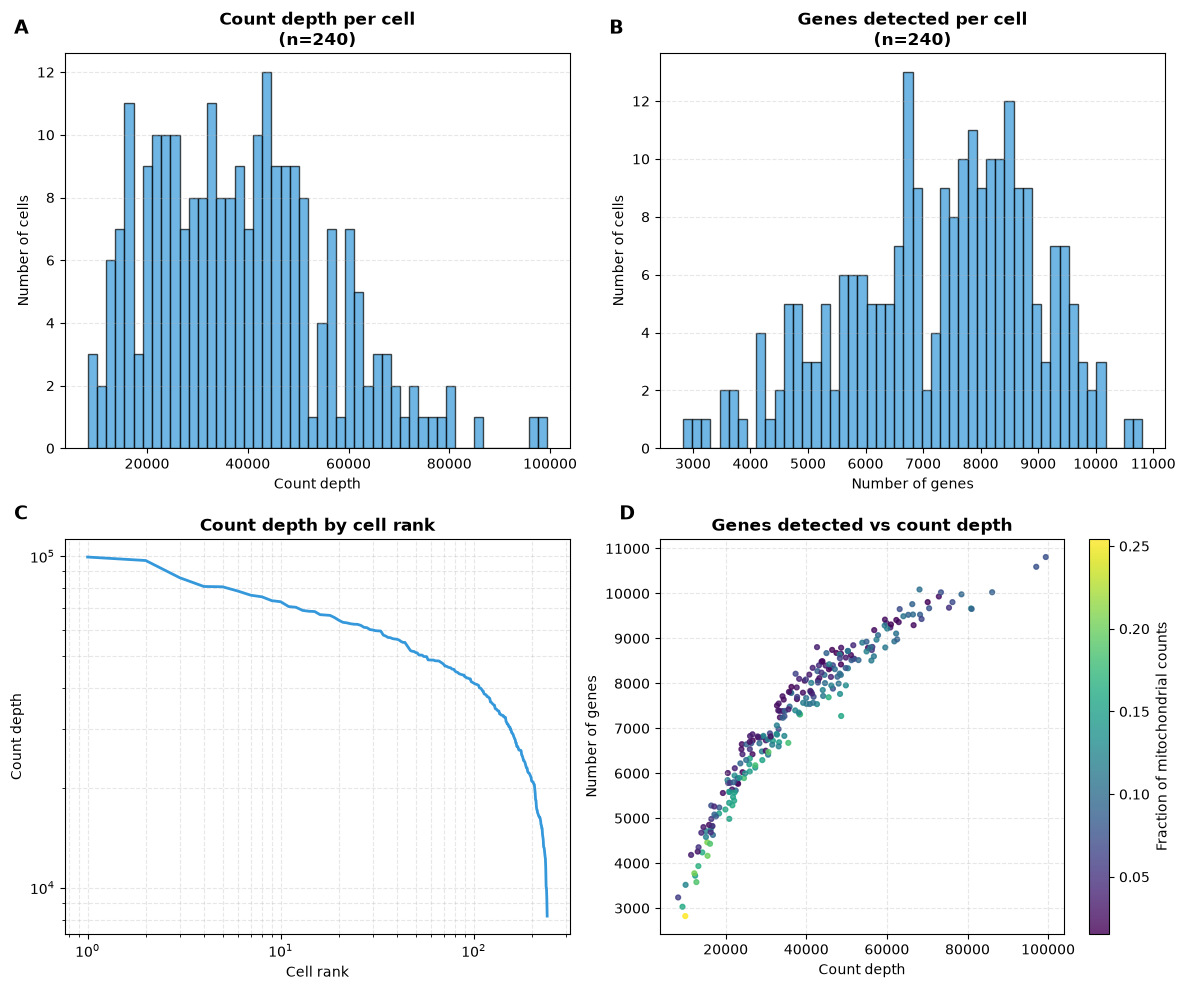

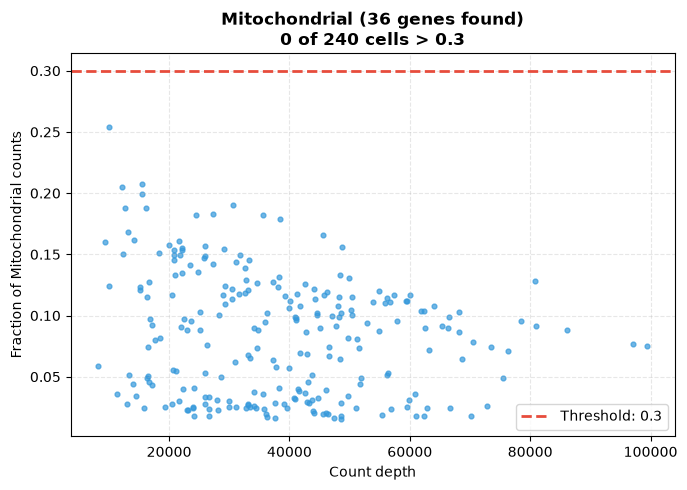

,too few counts,too few genes,high mito fraction,any
cell line,,,,
H1975,0,0,0,0
H2228,0,0,0,0
HCC827,0,0,0,0


0 of 240 cells fail the cell QC


In [7]:
from src.preprocessing.filters import high_fraction_mask, low_count_depth_mask, low_gene_count_mask
from src.preprocessing.gene_sets import mito_genes

from src.visualization import plot_gene_set_fraction_vs_count_depth, plot_qc_overview

# Count depth and genes per cell, with the dataset's count/gene thresholds (none are set for this dataset)
plot_qc_overview(
    counts,
    min_count_threshold=qc_config.min_count_threshold,
    max_count_threshold=qc_config.max_count_threshold,
    min_gene_threshold=qc_config.min_gene_threshold,
    max_gene_threshold=qc_config.max_gene_threshold,
    species=SPECIES,
)
# Mitochondrial fraction, with the threshold the pipeline filters on: cells above it (red) are removed
plot_gene_set_fraction_vs_count_depth(
    counts, mito_genes(SPECIES, annotation), "Mitochondrial", threshold=qc_config.mito_threshold)

# The masks the pipeline uses: True = the cell fails that check
failed = pd.DataFrame({
    "too few counts": low_count_depth_mask(counts, qc_config.min_count_threshold),
    "too few genes": low_gene_count_mask(counts, qc_config.min_gene_threshold),
    "high mito fraction": high_fraction_mask(
        counts, mito_genes(SPECIES, annotation), qc_config.mito_threshold, "mitochondrial"),
})
failed["any"] = failed.any(axis=1)
display(failed.groupby(ground_truth).sum().rename_axis("cell line"))
print(f"{int(failed['any'].sum())} of {len(counts)} cells fail the cell QC")

### 2.2 Gene filtering

`run_filtering_pipeline` applies the cell QC above, then drops the rRNA genes and the genes whose highest count is
below `min_gene_max_count`.

2026-11-21 12:25:30,929 | INFO | src.preprocessing.pipeline | Filtering...


2026-11-21 12:25:30,930 | INFO | src.preprocessing.pipeline | Input: 240 cells x 28142 genes


2026-11-21 12:25:30,958 | INFO | src.preprocessing.pipeline | Cells with count depth < None: 0


2026-11-21 12:25:30,958 | INFO | src.preprocessing.pipeline | Cells with count depth > None: 0


2026-11-21 12:25:30,958 | INFO | src.preprocessing.pipeline | Cells with genes detected < None: 0


2026-11-21 12:25:30,958 | INFO | src.preprocessing.pipeline | Cells with genes detected > None: 0


2026-11-21 12:25:30,959 | INFO | src.preprocessing.pipeline | Cells with high mitochondrial fraction: 0


2026-11-21 12:25:30,959 | INFO | src.preprocessing.pipeline | Dropped 0 cells failing cell QC


2026-11-21 12:25:31,007 | INFO | src.preprocessing.pipeline | Dropped 43 rRNA genes


2026-11-21 12:25:31,026 | INFO | src.preprocessing.pipeline | Output: 240 cells x 18567 genes


Before: 240 cells x 28142 genes
After:  240 cells x 18567 genes


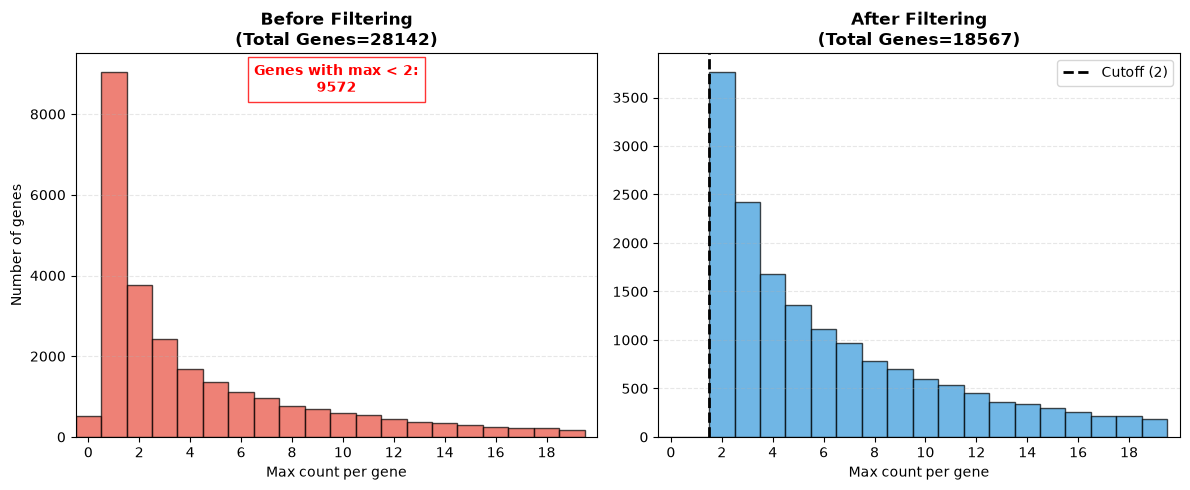

In [8]:
from src.preprocessing.pipeline import run_filtering_pipeline

filtered_counts = run_filtering_pipeline(counts, config=qc_config, species=SPECIES, annotation=annotation)
print(f"Before: {counts.shape[0]} cells x {counts.shape[1]} genes")
print(f"After:  {filtered_counts.shape[0]} cells x {filtered_counts.shape[1]} genes")

from src.visualization import plot_gene_max_count_distribution

plot_gene_max_count_distribution(counts, filtered_counts)

### 2.3 HVG selection and log-CPM normalization

The HVGs are scored on the **raw counts** (Seurat v3). Normalization runs on **all genes**, so each cell's library
size is its real sequencing depth; only then are the HVG columns kept.

raw counts


gene_id,ENSG00000251562,ENSG00000198727,ENSG00000198840,ENSG00000132432
cell_id,,,,
A1,9,82,70,23
A10,730,87,76,39
A11,54,134,67,257
A13,272,42,43,32


CPM


gene_id,ENSG00000251562,ENSG00000198727,ENSG00000198840,ENSG00000132432
cell_id,,,,
A1,574.90,5237.94,4471.41,1469.18
A10,10138.89,1208.33,1055.56,541.67
A11,1788.91,4439.14,2219.57,8513.88
A13,8075.29,1246.92,1276.61,950.03


ln(CPM + 1)


gene_id,ENSG00000251562,ENSG00000198727,ENSG00000198840,ENSG00000132432
cell_id,,,,
A1,6.36,8.56,8.41,7.29
A10,9.22,7.10,6.96,6.30
A11,7.49,8.40,7.71,9.05
A13,9.00,7.13,7.15,6.86


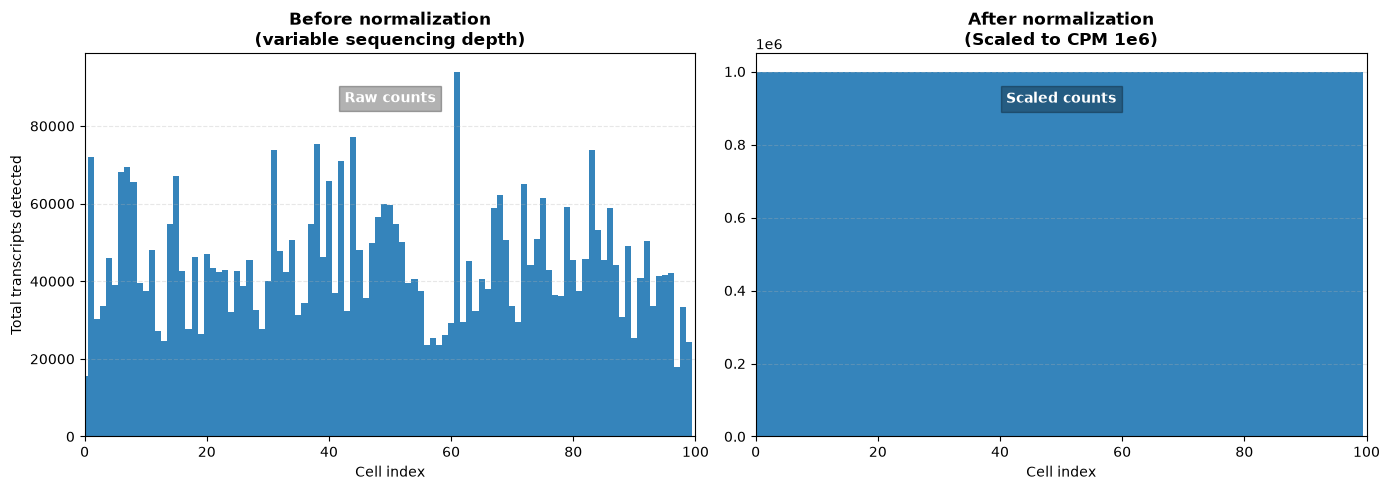

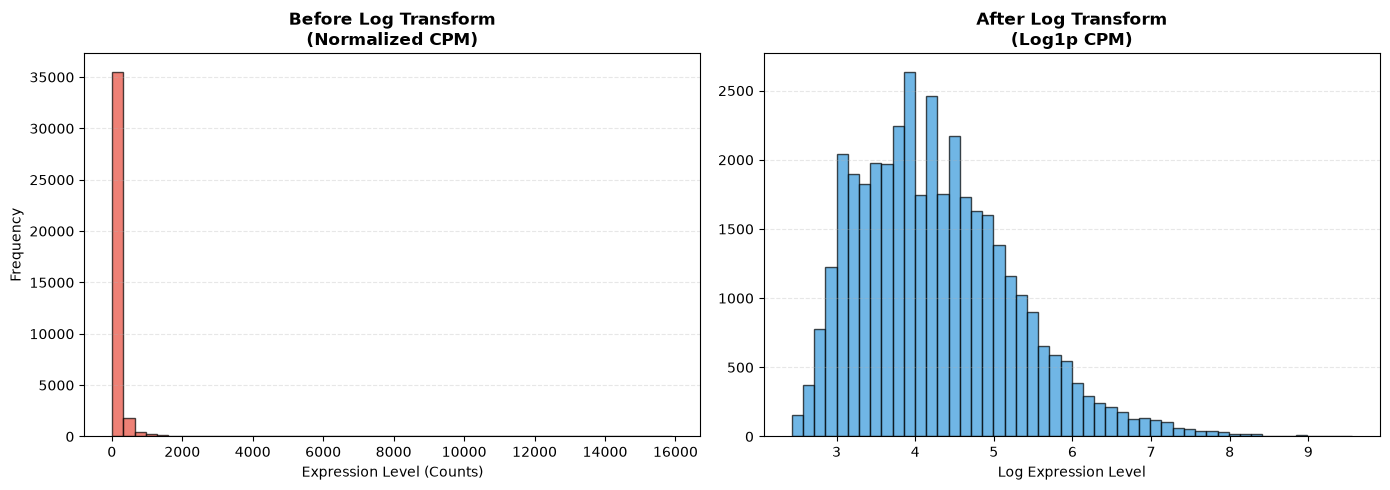

no_pca: 240 cells x 2000 genes (log-CPM of the HVGs)


In [9]:
from src.preprocessing.transforms import log_transform, normalize_by_library_size, select_hvgs_seurat_v3

hvgs = select_hvgs_seurat_v3(filtered_counts)
cpm = normalize_by_library_size(filtered_counts)   # each cell sums to 1,000,000
log_cpm = log_transform(cpm)                        # ln(x + 1)
no_pca = log_cpm.loc[:, hvgs]

example_genes = filtered_counts[hvgs].mean().nlargest(4).index
example_cells = filtered_counts.index[:4]
for name, frame in [("raw counts", filtered_counts), ("CPM", cpm), ("ln(CPM + 1)", log_cpm)]:
    print(name)
    display(frame.loc[example_cells, example_genes].round(2))

from src.visualization import plot_log_transform_comparison, plot_normalization_comparison

plot_normalization_comparison(filtered_counts, cpm)   # library size of 100 cells: before vs after CPM
plot_log_transform_comparison(cpm, log_cpm)           # nonzero expression values: before vs after ln(x + 1)
print(f"no_pca: {no_pca.shape[0]} cells x {no_pca.shape[1]} genes (log-CPM of the HVGs)")

### 2.4 PCA

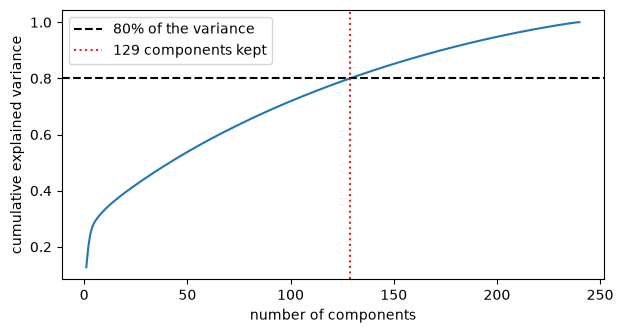

In [10]:
from sklearn.decomposition import PCA as SklearnPCA
from src.preprocessing import apply_pca

pca = apply_pca(no_pca, variance_ratio=RUN_CONFIG["pca_variance_ratio"])

# No plot in src/visualization.py for this one: refit the full PCA only to plot the curve apply_pca cuts
cumulative = np.cumsum(SklearnPCA(random_state=SEED).fit(no_pca).explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(np.arange(1, len(cumulative) + 1), cumulative)
ax.axhline(RUN_CONFIG["pca_variance_ratio"], color="black", ls="--", label="80% of the variance")
ax.axvline(pca.shape[1], color="tab:red", ls=":", label=f"{pca.shape[1]} components kept")
ax.set_xlabel("number of components")
ax.set_ylabel("cumulative explained variance")
ax.legend()
plt.show()

### Output

The data to cluster: each cell is now a point in the space of the principal components.

In [11]:
print(f"pca: {pca.shape[0]} cells x {pca.shape[1]} principal components")
display(pca.iloc[:5, :6].round(2))

pca: 240 cells x 129 principal components


,PC1,PC2,PC3,PC4,PC5,PC6
cell_id,,,,,,
A1,-19.69,23.69,-8.24,9.29,11.85,4.30
A10,47.67,-13.45,15.30,9.01,-10.74,-8.34
A11,-20.99,-25.99,-9.77,9.38,-5.10,-6.78
A13,51.42,-4.44,10.66,2.58,-7.89,9.02
A14,-17.89,-23.88,-11.14,3.40,-0.55,-3.08


In [12]:
# Check: the stages above give the same result as the single call preprocess.py makes
from src.preprocessing import preprocess_data

pipeline_no_pca, pipeline_hvgs = preprocess_data(
    counts, norm_method=NORM_METHOD, species=SPECIES, preprocessing_config=qc_config, annotation=annotation)
assert pipeline_hvgs == hvgs
assert np.allclose(pipeline_no_pca, no_pca)
assert np.allclose(apply_pca(pipeline_no_pca, variance_ratio=RUN_CONFIG["pca_variance_ratio"]), pca)
print("Step by step == preprocess.py")

2026-11-21 12:25:32,116 | INFO | src.preprocessing.pipeline | Filtering...


2026-11-21 12:25:32,117 | INFO | src.preprocessing.pipeline | Input: 240 cells x 28142 genes


2026-11-21 12:25:32,147 | INFO | src.preprocessing.pipeline | Cells with count depth < None: 0


2026-11-21 12:25:32,148 | INFO | src.preprocessing.pipeline | Cells with count depth > None: 0


2026-11-21 12:25:32,148 | INFO | src.preprocessing.pipeline | Cells with genes detected < None: 0


2026-11-21 12:25:32,148 | INFO | src.preprocessing.pipeline | Cells with genes detected > None: 0


2026-11-21 12:25:32,148 | INFO | src.preprocessing.pipeline | Cells with high mitochondrial fraction: 0


2026-11-21 12:25:32,149 | INFO | src.preprocessing.pipeline | Dropped 0 cells failing cell QC


2026-11-21 12:25:32,193 | INFO | src.preprocessing.pipeline | Dropped 43 rRNA genes


2026-11-21 12:25:32,209 | INFO | src.preprocessing.pipeline | Output: 240 cells x 18567 genes


Step by step == preprocess.py


---
## Step 3 · `benchmark`: cluster with Leiden and score the clusters

Clusters the PCA data, then scores the clusters:

- **external metrics** compare the clusters with the ground truth: ARI, NMI, Jaccard (higher is better)
- **internal metrics** score the clusters on the data alone: silhouette, Calinski-Harabasz (higher is better), Davies-Bouldin (lower is better)

This is the `default` run, so there are no tuned parameters: Leiden runs with resolution 1.0.

*In the pipeline:* `scripts/benchmark.py` saves `outputs/runs/log_cpm/pca/default/leiden_labels.csv` (the clusters)
and `leiden.json` (the metrics).

### Input

The PCA data from step 2 and the ground truth labels from step 1.

In [13]:
print(f"Data to cluster: {pca.shape[0]} cells x {pca.shape[1]} components")
print(f"Ground truth:    {ground_truth.nunique()} cell lines")

Data to cluster: 240 cells x 129 components
Ground truth:    3 cell lines


### Run

What `leiden_strategy` does: scanpy builds a k-nearest-neighbor graph of the cells (15 neighbors, in PCA space),
then the Leiden algorithm splits that graph into communities that are more connected inside than between each other.
`resolution` sets how fine the split is.

In [14]:
import scanpy as sc
from src.clustering.registry import get_clustering_strategy
from src.profiling import measure_resources

# The neighbor graph Leiden works on, built here only to show it
adata = sc.AnnData(pca)
sc.pp.neighbors(adata, use_rep="X", random_state=SEED)
print(f"kNN graph: {adata.n_obs} cells, {adata.obsp['connectivities'].nnz // 2} edges")

cluster = get_clustering_strategy(ALGORITHM)   # = leiden_strategy
with measure_resources() as resources:
    predicted = cluster(pca).rename("cluster")  # no kwargs: the default parameters
print(f"Clustering took {resources.wall_time_s:.1f}s")

kNN graph: 240 cells, 2820 edges
Clustering took 0.1s


In [15]:
from src.evaluation import evaluate_clustering_externally, evaluate_clustering_internally

metrics = {
    **evaluate_clustering_externally(predicted, ground_truth),
    **evaluate_clustering_internally(pca, predicted),
}

### Output

The predicted cluster of every cell, and the run's metrics.

In [16]:
print(f"predicted: one cluster per cell, {predicted.nunique()} clusters")
display(predicted.head())

print("Clusters vs cell lines:")
display(pd.crosstab(ground_truth.loc[predicted.index], predicted, rownames=["cell line"], colnames=["Leiden cluster"]))

display(pd.Series(metrics).round(3).to_frame("value"))

predicted: one cluster per cell, 4 clusters


cell_id
A1     0
A10    1
A11    2
A13    1
A14    2
Name: cluster, dtype: int8

Clusters vs cell lines:


Leiden cluster,0,1,2,3
cell line,,,,
H1975,85,0,0,18
H2228,0,67,0,0
HCC827,0,0,70,0


,value
ari,0.877
nmi,0.916
jaccard,0.845
silhouette,0.119
calinski_harabasz,25.519
davies_bouldin,2.998


---
## Step 4 · `permutation_test`: is the run better than random labels?

The predicted labels are shuffled across cells many times. A shuffle keeps the number and sizes of the clusters
but breaks any link to the data and the truth. Scoring each shuffle with the same metrics gives a **null distribution**
per metric; the run's **empirical p-value** is the share of shuffles that score at least as well as the run.

*In the pipeline:* `scripts/permutation_test.py` saves `outputs/runs/log_cpm/pca/default/leiden_null.npz`.

### Input

The PCA data (for the internal metrics), the predicted labels from step 3 and the ground truth.

In [17]:
N_PERMUTATIONS = RUN_CONFIG["permutation_test"]["n_permutations"]
print(f"{N_PERMUTATIONS} shuffles of the labels of {len(predicted)} cells")

1000 shuffles of the labels of 240 cells


### Run

In [18]:
from src.evaluation import compute_null_distribution, summarize_null

null = compute_null_distribution(pca, predicted, ground_truth, n_permutations=N_PERMUTATIONS, seed=SEED)

2026-11-21 12:25:38,111 | INFO | src.evaluation.permutation | Scored 100/1000 permutations


2026-11-21 12:25:38,373 | INFO | src.evaluation.permutation | Scored 200/1000 permutations


2026-11-21 12:25:38,636 | INFO | src.evaluation.permutation | Scored 300/1000 permutations


2026-11-21 12:25:38,899 | INFO | src.evaluation.permutation | Scored 400/1000 permutations


2026-11-21 12:25:39,161 | INFO | src.evaluation.permutation | Scored 500/1000 permutations


2026-11-21 12:25:39,423 | INFO | src.evaluation.permutation | Scored 600/1000 permutations


2026-11-21 12:25:39,687 | INFO | src.evaluation.permutation | Scored 700/1000 permutations


2026-11-21 12:25:39,950 | INFO | src.evaluation.permutation | Scored 800/1000 permutations


2026-11-21 12:25:40,212 | INFO | src.evaluation.permutation | Scored 900/1000 permutations


2026-11-21 12:25:40,475 | INFO | src.evaluation.permutation | Scored 1000/1000 permutations


### Output

null: 1000 shuffles x 6 metrics


,ari,nmi,jaccard,silhouette,calinski_harabasz,davies_bouldin
0,-0.008,0.003,0.183,-0.009,0.689,13.643
1,0.010,0.021,0.192,-0.020,1.109,11.580
2,0.002,0.009,0.188,-0.013,0.903,11.774
3,-0.004,0.010,0.185,-0.020,0.955,12.182
4,-0.003,0.008,0.186,-0.010,0.817,12.597


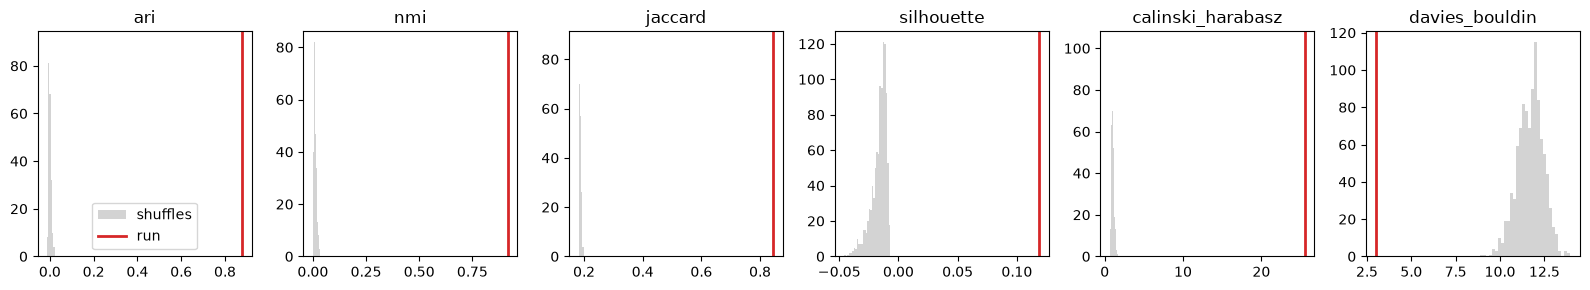

,value
ari_null_mean,0.000109
ari_pvalue,0.000999
nmi_null_mean,0.010935
nmi_pvalue,0.000999
jaccard_null_mean,0.187387
jaccard_pvalue,0.000999
silhouette_null_mean,-0.016541
silhouette_pvalue,0.000999
calinski_harabasz_null_mean,1.001748
calinski_harabasz_pvalue,0.000999


In [19]:
print(f"null: {null.shape[0]} shuffles x {null.shape[1]} metrics")
display(null.head().round(3))

# No plot in src/visualization.py for this one: each metric's shuffle scores vs the run's score
fig, axes = plt.subplots(1, len(null.columns), figsize=(16, 3))
for ax, metric in zip(axes, null.columns):
    ax.hist(null[metric], bins=30, color="lightgray", label="shuffles")
    ax.axvline(metrics[metric], color="tab:red", lw=2, label="run")
    ax.set_title(metric)
axes[0].legend()
plt.tight_layout()
plt.show()

null_summary = summarize_null(metrics, null)
display(pd.Series(null_summary).to_frame("value"))

---
## Step 5 · `aggregate_runs`: the run as a row of the results table

In the full workflow this gathers every run of the dataset (all algorithms × normalizations × PCA options × params)
into a table with one row per run. Here there is a single run, so the table has one row, with the same columns.

*In the pipeline:* `scripts/aggregate_runs.py` saves `outputs/results.tsv` and `outputs/labels.tsv`.

### Input

The metrics (step 3), the null summary (step 4) and the clustering resources (step 3).

### Run

In [20]:
results = pd.DataFrame([{
    "dataset": ACCESSION,
    "algorithm": ALGORITHM,
    "normalization": NORM_METHOD,
    "pca": "pca",
    "params": "default",
    "n_cells": pca.shape[0],
    "n_features": pca.shape[1],
    **metrics,
    **null_summary,
    **{f"clustering_{name}": value for name, value in resources.as_dict().items()},
}])

### Output

In [21]:
display(results.T.rename(columns={0: "value"}))

,value
dataset,GSE118767_celseq2_3cl
algorithm,leiden
normalization,log_cpm
pca,pca
params,default
n_cells,240
n_features,129
ari,0.877367
nmi,0.9156
jaccard,0.845126


---
## Step 6 · `embed`: 2D UMAP, for the plots

Runs beside the benchmark, not after it: the PCA data is embedded in 2D with UMAP to **look** at the clusters.
The UMAP is never clustered or scored.

*In the pipeline:* `scripts/embed.py` saves `processed/log_cpm/umap.csv.gz`.

### Run

In [22]:
from src.preprocessing import apply_umap

umap = apply_umap(pca)

### Output: ground truth vs Leiden

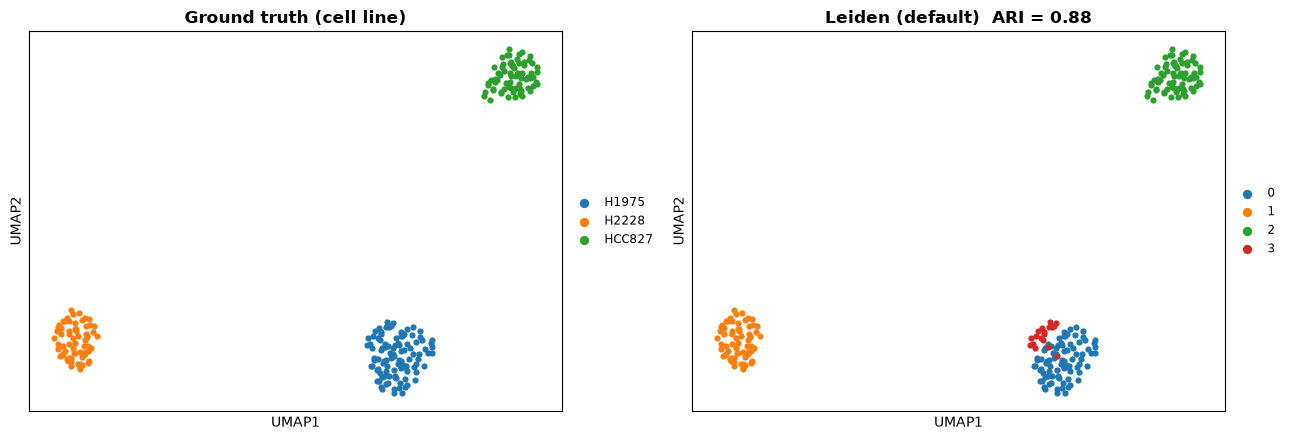

In [23]:
from src.visualization import plot_umap

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_umap(umap, ground_truth, title="Ground truth (cell line)", ax=axes[0])
plot_umap(umap, predicted, title=f"Leiden (default)  ARI = {metrics['ari']:.2f}", ax=axes[1])
plt.tight_layout()
plt.show()

---
## Summary: what each step produced

In [24]:
pd.DataFrame([
    ("prepare", "counts", f"{counts.shape[0]} cells x {counts.shape[1]} genes", "interim/counts.csv.gz"),
    ("prepare", "ground_truth", f"{len(ground_truth)} labels, {ground_truth.nunique()} cell lines", "interim/ground_truth_labels.csv"),
    ("preprocess", "no_pca", f"{no_pca.shape[0]} cells x {no_pca.shape[1]} HVGs", "processed/log_cpm/no_pca.csv.gz"),
    ("preprocess", "pca", f"{pca.shape[0]} cells x {pca.shape[1]} PCs", "processed/log_cpm/pca.csv.gz"),
    ("benchmark", "predicted", f"{predicted.nunique()} clusters", "outputs/runs/log_cpm/pca/default/leiden_labels.csv"),
    ("benchmark", "metrics", f"ARI {metrics['ari']:.3f}, silhouette {metrics['silhouette']:.3f}", "outputs/runs/log_cpm/pca/default/leiden.json"),
    ("permutation_test", "null", f"{len(null)} shuffles x {null.shape[1]} metrics", "outputs/runs/log_cpm/pca/default/leiden_null.npz"),
    ("aggregate_runs", "results", f"{len(results)} row x {results.shape[1]} columns", "outputs/results.tsv"),
    ("embed", "umap", f"{umap.shape[0]} cells x 2", "processed/log_cpm/umap.csv.gz"),
], columns=["step", "variable", "contents", f"pipeline file (under data/datasets/{ACCESSION}/)"])

,step,variable,contents,pipeline file (under data/datasets/GSE118767_celseq2_3cl/)
0,prepare,counts,240 cells x 28142 genes,interim/counts.csv.gz
1,prepare,ground_truth,"240 labels, 3 cell lines",interim/ground_truth_labels.csv
2,preprocess,no_pca,240 cells x 2000 HVGs,processed/log_cpm/no_pca.csv.gz
3,preprocess,pca,240 cells x 129 PCs,processed/log_cpm/pca.csv.gz
4,benchmark,predicted,4 clusters,outputs/runs/log_cpm/pca/default/leiden_labels...
5,benchmark,metrics,"ARI 0.877, silhouette 0.119",outputs/runs/log_cpm/pca/default/leiden.json
6,permutation_test,null,1000 shuffles x 6 metrics,outputs/runs/log_cpm/pca/default/leiden_null.npz
7,aggregate_runs,results,1 row x 29 columns,outputs/results.tsv
8,embed,umap,240 cells x 2,processed/log_cpm/umap.csv.gz
